# Movie Review Sentiment Filter for a Ticket-Booking App
**LLM Mini Project — MP-C01 | GPT-2 124M classification fine-tuning**

This notebook builds a binary sentiment classifier for IMDb movie reviews. It samples approximately 6,000 balanced reviews, compares keeping the **beginning** of long reviews with keeping the **ending**, evaluates accuracy and F1 before and after fine-tuning, tests ten self-written reviews, and launches a Gradio demo.

> **Important:** Run all cells in order. Training results depend on the runtime and must be copied from the actual outputs into your report. This notebook does not fabricate accuracy/F1 values. A GPU runtime (Google Colab: Runtime → Change runtime type → T4 GPU) is strongly recommended.

## 1. Install dependencies
Run this cell first. The notebook is designed for Google Colab; choose a GPU runtime if available.


In [ ]:
%pip -q install transformers datasets scikit-learn pandas matplotlib seaborn gradio accelerate

## 2. Imports and reproducibility

In [ ]:
import os
import random
import time
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from transformers import (
    AutoTokenizer,
    GPT2ForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    set_seed,
)

SEED = 123
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
set_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)
if DEVICE == "cpu":
    print("Warning: GPT-2 fine-tuning may be very slow on CPU. Prefer a Colab GPU.")

Device: cuda


## 3. Load IMDb dataset and create a small balanced subset
For quick testing, this version uses 200 reviews total: 100 negative and 100 positive. For a final submission, use a larger dataset if your instructor expects it.


In [ ]:
!pip install -U datasets huggingface_hub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 20.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 855.2/855.2 kB 23.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 77.1 MB/s  0:00:00
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 23.0.1
    Uninstalling pyarrow-23.0.1:
      Successfully uninstalled pyarrow-23.0.1
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface_hub 1.33.0
    Uninstalling huggingface_hub-1.33.0:
      Successfully uninstalled huggingface_hub-1.33.0
  Attempting uninstall: datasets
    Found existing installation: datasets 4.8.5
    Uninstalling datasets-4.8.5:
      Successfully uninstalled datasets-4.8.5
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [datasets]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.41.0 require

In [ ]:
raw = load_dataset("stanfordnlp/imdb")
print(raw)
print("Original training rows:", len(raw["train"]))
print("Original test rows:", len(raw["test"]))
print("Training label counts:", pd.Series(raw["train"]["label"]).value_counts().sort_index().to_dict())

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  except ColabError as e:


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

...

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})
Original training rows: 25000
Original test rows: 25000
Training label counts: {0: 12500, 1: 12500}


Subset rows after basic cleaning: 200
Label counts (0=negative, 1=positive):


,count
label,
negative,100
positive,100


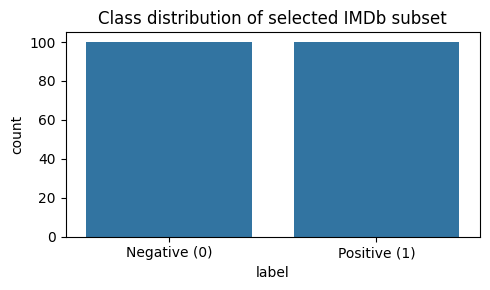

In [ ]:
# Select a small, balanced dataset of 200 reviews (100 from each class)
train_df = pd.DataFrame({"text": raw["train"]["text"], "label": raw["train"]["label"]})
balanced_parts = []
for label in [0, 1]:
    part = train_df[train_df["label"] == label].sample(n=100, random_state=SEED)
    balanced_parts.append(part)

data = pd.concat(balanced_parts, ignore_index=True)
data = data.dropna(subset=["text", "label"])
data["text"] = data["text"].astype(str).str.strip()
data = data[data["text"].str.len() > 0].drop_duplicates(subset=["text"])
data = data.sample(frac=1, random_state=SEED).reset_index(drop=True)

print("Subset rows after basic cleaning:", len(data))
print("Label counts (0=negative, 1=positive):")
display(data["label"].value_counts().sort_index().rename(index={0:"negative", 1:"positive"}).to_frame("count"))

plt.figure(figsize=(5, 3))
sns.countplot(data=data, x="label")
plt.xticks([0, 1], ["Negative (0)", "Positive (1)"])
plt.title("Class distribution of selected IMDb subset")
plt.tight_layout()
plt.show()


## 4. Train/validation/test split
The split is stratified so that both sentiment classes are represented in similar proportions.

In [ ]:
train_texts, temp_texts, train_labels, temp_labels = train_test_split(
    data["text"].tolist(), data["label"].astype(int).tolist(),
    test_size=0.30, random_state=SEED, stratify=data["label"].tolist()
)
val_texts, test_texts, val_labels, test_labels = train_test_split(
    temp_texts, temp_labels, test_size=0.50,
    random_state=SEED, stratify=temp_labels
)

print(f"Train: {len(train_texts)}")
print(f"Validation: {len(val_texts)}")
print(f"Test: {len(test_texts)}")
print("Total:", len(train_texts) + len(val_texts) + len(test_texts))

Train: 140
Validation: 30
Test: 30
Total: 200


## 5. Load GPT-2 tokenizer and pretrained GPT-2 124M
GPT-2 does not define a separate padding token by default, so its end-of-text token is used for padding. The model adds a two-class sequence-classification head.

In [ ]:
MODEL_NAME = "gpt2"  # GPT-2 small, approximately 124M parameters
MAX_LENGTH = 256
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token

id2label = {0: "negative", 1: "positive"}
label2id = {"negative": 0, "positive": 1}

print("Tokenizer:", MODEL_NAME)
print("Vocab size:", tokenizer.vocab_size)
print("Pad token ID:", tokenizer.pad_token_id)
print("Maximum review length:", MAX_LENGTH)

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Tokenizer: gpt2
Vocab size: 50257
Pad token ID: 50256
Maximum review length: 256


## 6. Tokenization and PyTorch datasets
The default training condition keeps the first 256 tokens of a review (right truncation). Later, the evaluation comparison changes the tokenizer to left truncation, which keeps the final 256 tokens. Padding is applied to each batch.

In [ ]:
from torch.utils.data import Dataset

class ReviewDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length=256, truncation_side="right"):
        self.texts = list(texts)
        self.labels = list(labels)
        self.tokenizer = tokenizer
        self.max_length = max_length
        self.truncation_side = truncation_side

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        old_side = self.tokenizer.truncation_side
        self.tokenizer.truncation_side = self.truncation_side
        try:
            encoded = self.tokenizer(
                self.texts[idx],
                max_length=self.max_length,
                truncation=True,
                padding=False,
                return_tensors=None,
            )
        finally:
            self.tokenizer.truncation_side = old_side

        item = {key: torch.tensor(value, dtype=torch.long) for key, value in encoded.items()}
        item["labels"] = torch.tensor(int(self.labels[idx]), dtype=torch.long)
        return item

data_collator = DataCollatorWithPadding(tokenizer=tokenizer, padding=True, return_tensors="pt")

train_ds = ReviewDataset(train_texts, train_labels, tokenizer, MAX_LENGTH, "right")
val_ds = ReviewDataset(val_texts, val_labels, tokenizer, MAX_LENGTH, "right")
test_ds = ReviewDataset(test_texts, test_labels, tokenizer, MAX_LENGTH, "right")

print("Dataset examples:", len(train_ds), len(val_ds), len(test_ds))
print("One encoded example keys:", train_ds[0].keys())

Dataset examples: 140 30 30
One encoded example keys: dict_keys(['input_ids', 'attention_mask', 'labels'])


## 7. Evaluation metrics and baseline model
The baseline is the pretrained GPT-2 model with a newly initialized classification head, before task-specific training. Since that head is random, its baseline score may be near chance or otherwise unstable. We measure it rather than assuming a value.

In [ ]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "f1": f1_score(labels, preds, average="binary", zero_division=0),
    }

def predict_texts(model, texts, truncation_side="right", batch_size=16):
    model.eval()
    predictions, confidences = [], []
    old_side = tokenizer.truncation_side
    tokenizer.truncation_side = truncation_side
    try:
        for start in range(0, len(texts), batch_size):
            batch_texts = texts[start:start+batch_size]
            enc = tokenizer(
                batch_texts,
                max_length=MAX_LENGTH,
                truncation=True,
                padding=True,
                return_tensors="pt",
            )
            enc = {k: v.to(model.device) for k, v in enc.items()}
            with torch.no_grad():
                logits = model(**enc).logits
                probs = torch.softmax(logits, dim=-1)
            conf, pred = probs.max(dim=-1)
            predictions.extend(pred.cpu().numpy().tolist())
            confidences.extend(conf.cpu().numpy().tolist())
    finally:
        tokenizer.truncation_side = old_side
    return np.array(predictions), np.array(confidences)

def metric_row(name, y_true, y_pred):
    return {
        "Condition": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "F1-score": f1_score(y_true, y_pred, average="binary", zero_division=0),
    }

baseline_model = GPT2ForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2, id2label=id2label, label2id=label2id
)
baseline_model.config.pad_token_id = tokenizer.pad_token_id
baseline_model.to(DEVICE)

baseline_preds, baseline_conf = predict_texts(baseline_model, test_texts, "right")
baseline_row = metric_row("Before fine-tuning (keep beginning)", test_labels, baseline_preds)
display(pd.DataFrame([baseline_row]))
print(classification_report(test_labels, baseline_preds, target_names=["negative", "positive"], zero_division=0))

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] GPT2ForSequenceClassification LOAD REPORT from: gpt2
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


,Condition,Accuracy,F1-score
0,Before fine-tuning (keep beginning),0.5,0.666667


              precision    recall  f1-score   support

    negative       0.00      0.00      0.00        15
    positive       0.50      1.00      0.67        15

    accuracy                           0.50        30
   macro avg       0.25      0.50      0.33        30
weighted avg       0.25      0.50      0.33        30



## 8. Fine-tune GPT-2 for sentiment classification
The model is trained on the training split and selected using validation loss. If you run out of GPU memory, reduce `BATCH_SIZE` to 2 or 4.

In [ ]:
BATCH_SIZE = 4 if DEVICE == "cuda" else 2
EPOCHS = 2
LEARNING_RATE = 5e-5
WEIGHT_DECAY = 0.01
OUTPUT_DIR = "./gpt2_imdb_sentiment"

model = GPT2ForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2, id2label=id2label, label2id=label2id
)
model.config.pad_token_id = tokenizer.pad_token_id
model.config.use_cache = False  # recommended during training

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    num_train_epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    weight_decay=WEIGHT_DECAY,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    logging_strategy="steps",
    logging_steps=50,
    save_total_limit=2,
    seed=SEED,
    fp16=(DEVICE == "cuda"),
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

start_time = time.time()
train_result = trainer.train()
training_seconds = time.time() - start_time
print(f"Training time: {training_seconds/60:.2f} minutes")
print("Training metrics:", train_result.metrics)
print("Validation metrics:", trainer.evaluate())

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] GPT2ForSequenceClassification LOAD REPORT from: gpt2
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,No log,0.750562,0.466667,0.529412


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

## 9. Plot training and validation loss

,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_accuracy,eval_f1,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,1.005306,10.035133,0.000033,0.714286,50,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,1.000000,70,0.803821,0.466667,0.636364,17.4716,1.717,0.859,NaN,NaN,NaN,NaN,NaN
2,0.547727,14.418470,0.000015,1.428571,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,2.000000,140,0.685084,0.700000,0.727273,18.6514,1.608,0.804,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,2.000000,140,NaN,NaN,NaN,NaN,NaN,NaN,707.649,0.396,0.198,3.322960e+13,0.652707
5,NaN,NaN,NaN,2.000000,140,0.685084,0.700000,0.727273,18.2859,1.641,0.820,NaN,NaN,NaN,NaN,NaN


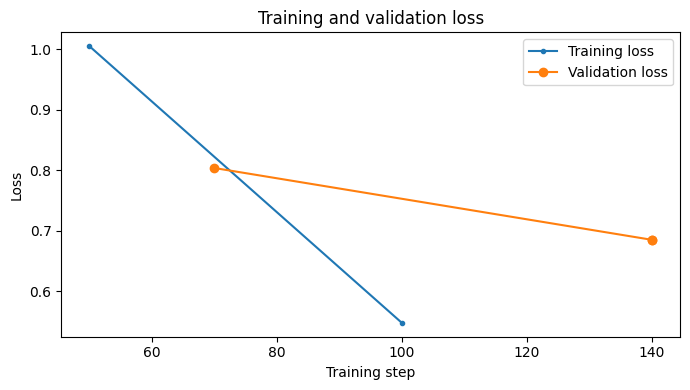

In [ ]:
history = pd.DataFrame(trainer.state.log_history)
display(history.tail(10))

if "loss" in history.columns:
    train_loss = history.dropna(subset=["loss"])
    plt.figure(figsize=(7, 4))
    plt.plot(train_loss["step"], train_loss["loss"], marker=".", label="Training loss")
    if "eval_loss" in history.columns:
        val_loss = history.dropna(subset=["eval_loss"])
        if not val_loss.empty:
            plt.plot(val_loss["step"], val_loss["eval_loss"], marker="o", label="Validation loss")
    plt.xlabel("Training step")
    plt.ylabel("Loss")
    plt.title("Training and validation loss")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("Loss values were not present in the training log.")

## 10. Evaluate after fine-tuning and compare start/end truncation
**Keep beginning** means retaining the first 256 tokens and discarding the tail (`truncation_side='right'`). **Keep ending** means retaining the last 256 tokens and discarding the beginning (`truncation_side='left'`). Both conditions are evaluated on the same held-out test reviews.

,Condition,Accuracy,F1-score
0,Before fine-tuning — keep beginning,0.500000,0.666667
1,After fine-tuning — keep beginning,0.900000,0.903226
2,After fine-tuning — keep ending,0.866667,0.882353


After fine-tuning, keep beginning:
              precision    recall  f1-score   support

    negative       0.93      0.87      0.90        15
    positive       0.88      0.93      0.90        15

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30

Confusion matrix (after fine-tuning, keep beginning):


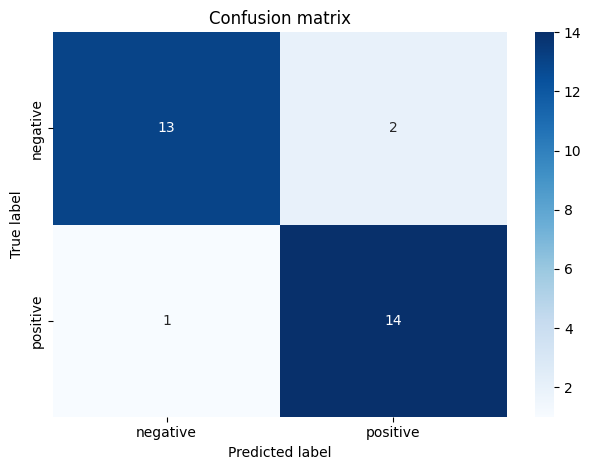

In [ ]:
model = trainer.model
model.config.use_cache = True
model.eval()

after_beginning_preds, after_beginning_conf = predict_texts(model, test_texts, "right")
after_ending_preds, after_ending_conf = predict_texts(model, test_texts, "left")

results = pd.DataFrame([
    metric_row("Before fine-tuning — keep beginning", test_labels, baseline_preds),
    metric_row("After fine-tuning — keep beginning", test_labels, after_beginning_preds),
    metric_row("After fine-tuning — keep ending", test_labels, after_ending_preds),
])
display(results)

print("After fine-tuning, keep beginning:")
print(classification_report(test_labels, after_beginning_preds, target_names=["negative", "positive"], zero_division=0))
print("Confusion matrix (after fine-tuning, keep beginning):")
cm = confusion_matrix(test_labels, after_beginning_preds)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["negative", "positive"],
            yticklabels=["negative", "positive"])
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Confusion matrix")
plt.tight_layout()
plt.show()

## 11. Error analysis — inspect actual mistakes
This cell prints up to three real misclassified examples from the held-out test set. Use these actual outputs in the report; do not invent error examples.

In [ ]:
errors = []
for text_value, true_label, pred_label in zip(test_texts, test_labels, after_beginning_preds):
    if int(true_label) != int(pred_label):
        errors.append({
            "Review (shortened)": text_value[:500] + ("..." if len(text_value) > 500 else ""),
            "Expected": id2label[int(true_label)],
            "Predicted": id2label[int(pred_label)],
        })
    if len(errors) == 3:
        break

if errors:
    display(pd.DataFrame(errors))
else:
    print("No misclassified examples found in this test split.")

,Review (shortened),Expected,Predicted
0,this film was shrouded in scandal for so long ...,negative,positive
1,"""Hitler, the rise of Evil"" is clearly produced...",positive,negative
2,Towards the end of this thriller Ally Sheedy's...,negative,positive


## 12. Test ten self-written reviews
These are manually authored examples, not examples copied from the dataset. Run all ten through the fine-tuned model and inspect the output, especially the mixed-opinion examples.

In [ ]:
custom_reviews = [
    "An excellent film with a moving story and superb acting.",
    "The movie was dull, predictable, and poorly acted.",
    "The visuals were beautiful, but the story was painfully slow.",
    "I loved the soundtrack and the lead performance.",
    "A disappointing film that wasted a promising idea.",
    "The first half was funny, while the ending felt rushed and confusing.",
    "The acting was average, but the clever plot kept me interested.",
    "I regret watching this movie because almost nothing worked.",
    "It was not perfect, yet its heartfelt characters made it worthwhile.",
    "The film had some good scenes, but overall it was a letdown.",
]

custom_preds, custom_conf = predict_texts(model, custom_reviews, "right")
custom_results = pd.DataFrame({
    "Review": custom_reviews,
    "Predicted sentiment": [id2label[int(x)] for x in custom_preds],
    "Confidence": np.round(custom_conf, 4),
})
display(custom_results)

,Review,Predicted sentiment,Confidence
0,An excellent film with a moving story and supe...,positive,0.9543
1,"The movie was dull, predictable, and poorly ac...",positive,0.7590
2,"The visuals were beautiful, but the story was ...",positive,0.8064
3,I loved the soundtrack and the lead performance.,positive,0.9396
4,A disappointing film that wasted a promising i...,positive,0.7725
5,"The first half was funny, while the ending fel...",positive,0.8020
6,"The acting was average, but the clever plot ke...",positive,0.8874
7,I regret watching this movie because almost no...,positive,0.7532
8,"It was not perfect, yet its heartfelt characte...",positive,0.9297
9,"The film had some good scenes, but overall it ...",positive,0.8406


## 13. Save the trained model and tokenizer

In [ ]:
FINAL_MODEL_DIR = "./movie_review_sentiment_model"
os.makedirs(FINAL_MODEL_DIR, exist_ok=True)
model.save_pretrained(FINAL_MODEL_DIR)
tokenizer.save_pretrained(FINAL_MODEL_DIR)

# Save the measured results and self-written-review predictions for use in the report.
results.to_csv(os.path.join(FINAL_MODEL_DIR, "evaluation_results.csv"), index=False)
custom_results.to_csv(os.path.join(FINAL_MODEL_DIR, "custom_review_predictions.csv"), index=False)
with open(os.path.join(FINAL_MODEL_DIR, "experiment_summary.json"), "w") as f:
    json.dump({
        "seed": SEED,
        "dataset_subset_size": int(len(data)),
        "train_size": int(len(train_texts)),
        "validation_size": int(len(val_texts)),
        "test_size": int(len(test_texts)),
        "max_length": MAX_LENGTH,
        "epochs": EPOCHS,
        "batch_size": BATCH_SIZE,
        "learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "training_seconds": training_seconds,
        "results": results.to_dict(orient="records"),
    }, f, indent=2)

print("Saved model and experiment outputs to:", FINAL_MODEL_DIR)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved model and experiment outputs to: ./movie_review_sentiment_model


## 14. Gradio application
Run this cell to launch a simple interface. It displays the predicted sentiment and model confidence. Confidence is a model score, not a guarantee that the prediction is correct.

In [ ]:
import gradio as gr

def classify_review(review):
    if review is None or not review.strip():
        return "Please enter a movie review.", {}
    preds, confs = predict_texts(model, [review.strip()], "right", batch_size=1)
    pred = int(preds[0])
    probs = None
    # Recompute the full two-class probability distribution for the interface.
    model.eval()
    enc = tokenizer(
        review.strip(), max_length=MAX_LENGTH, truncation=True,
        padding=True, return_tensors="pt"
    )
    enc = {k: v.to(model.device) for k, v in enc.items()}
    with torch.no_grad():
        logits = model(**enc).logits
        probabilities = torch.softmax(logits, dim=-1)[0].cpu().numpy()
    label = id2label[pred]
    summary = f"Predicted sentiment: {label.upper()} | Confidence: {float(probabilities[pred]):.2%}"
    scores = {"Negative": float(probabilities[0]), "Positive": float(probabilities[1])}
    return summary, scores

demo = gr.Interface(
    fn=classify_review,
    inputs=gr.Textbox(lines=6, label="Enter a movie review", placeholder="Type or paste a review here..."),
    outputs=[gr.Textbox(label="Prediction"), gr.Label(label="Class probabilities")],
    title="Movie Review Sentiment Filter",
    description="Classifies a movie review as positive or negative. Predictions may be incorrect, especially for sarcasm or mixed opinions.",
    examples=[
        ["The acting was excellent and the story kept me engaged."],
        ["The plot was boring and the performances were weak."],
        ["The visuals were great, but the story was too slow."]
    ],
)
demo.launch(share=False, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

## 15. Values to transfer to the report

After all cells run successfully, use the actual outputs to fill the report:

- **Dataset:** subset size and exact train/validation/test sizes from Sections 3–4.
- **Training setup:** epoch count, batch size, learning rate, hardware and training time.
- **Before/after evaluation:** accuracy and F1 from the `results` table.
- **Truncation experiment:** compare “After fine-tuning — keep beginning” with “After fine-tuning — keep ending”.
- **Error analysis:** copy the real examples printed in Section 11.
- **Ten custom reviews:** copy the predictions from Section 12.
- **Figures:** save the class distribution, loss curve, confusion matrix, and a screenshot of the running Gradio interface.
- **Appendix:** include this notebook's shareable link and complete source code.

### Notes
1. This implementation uses Hugging Face's pretrained GPT-2 sequence-classification model, which is a practical implementation of GPT-2 124M fine-tuning. If your instructor specifically requires the custom `GPTModel` implementation from the course textbook, check whether you must replace the Hugging Face model with the course-provided model code.
2. The classification head is newly initialized, so baseline results are a measured reference rather than a meaningful pretrained sentiment classifier.
3. If your environment uses a newer Transformers release and reports that `evaluation_strategy` is unsupported, replace it with `eval_strategy="epoch"` in the `TrainingArguments` cell.
4. Do not report any metric until the relevant cell has run successfully.

In [1]:

import sys
import torch
import transformers
import datasets
import gradio
import numpy
import sklearn

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("Gradio:", gradio.__version__)
print("NumPy:", numpy.__version__)
print("Scikit-learn:", sklearn.__version__)
print("CUDA available:", torch.cuda.is_available())


Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
Transformers: 5.20.2
Datasets: 4.8.5
Gradio: 6.30.0
NumPy: 2.1.3
Scikit-learn: 1.6.1
CUDA available: True
